# <span style="color:blue;font-weight:bold;font-size:1.1em">ANOVA</span>

In this notebook we will learn:

- When and how to conduct an ANOVA test using `scipy.stats.f_oneway`
- How to interpret and report the results


### <span style="color:purple;font-weight:bold;font-size:1.1em">Analysis of Variance</span>

Recall that we learned about the <span style="color:blue;font-weight:bold;font-size:1.1em"><b>Independent Samples $t$-Test</b></span>.  This was a test that allowed us to compare the average of a numeric variable between two groups or populations.

**Problem:** What if there are more than 2 groups or populations?

The <u>An</u>alysis <u>o</u>f <u>Va</u>riance Test will handle this situation. The null and alternative hypothesis are shown below:

- $H_0 :$ All groups have the same mean

- $H_a :$ At least one group has a different mean

In [97]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
import seaborn as sns
import scipy.stats as stats
from scipy.stats import gaussian_kde

In [98]:
def describe(data, var = None):
  if isinstance(data, Table):
    data = data.column(var)
  names = np.array(["Mean", "Std Dev", "Sample Size", "Min", "Q1", "Median", "Q3", "Max"])
  values = np.array([round(np.mean(data),1), round(stats.tstd(data),2), len(data) - 1, min(data), np.percentile(data, 25), np.median(data), np.percentile(data, 75), max(data)])
  tab = Table().with_columns('Names', names, 'Values', values)  ;  transposed_tab = Table().with_columns( zip(tab.column('Names'), tab.column('Values')) ).show()
  return

def describes(data, num, group):
  dat = data.column(num)  ;  group_var = data.column(group)  ;  groups = np.unique(group_var)  ;  rows = []  ;  tab = Table(['Group', 'Mean', 'Std. Dev.', 'Sample Size', 'Min', 'Q1', 'Median', 'Q3', 'Max'])
  for g in groups:
    # Filter data for the current group
    sub_dat = dat[group_var == g]  ;    rows = [g, round(np.mean(sub_dat), 1), round(stats.tstd(sub_dat), 2), len(sub_dat) - 1, min(sub_dat), np.percentile(sub_dat, 25), np.median(sub_dat), np.percentile(sub_dat, 75), max(sub_dat)]        
    tab = tab.with_row(rows)
  tab.show()
  return 

def box(data, num = None, sm = False):
  if isinstance(data, Table):
    df = data.to_df()  ;  sns.boxplot(data=df, y=num, width=0.45, showmeans=sm)  ;
    plots.title(f'Boxplot of {num}')  ;  plots.xticks([], [])  ;  plots.show()  
  else:
    if num == True:
      sm = True  ;  num = 'Variable'
    if num == None:
      num = 'Variable'
    plots.figure(figsize=(6, 6))  ;  plots.boxplot(data, widths = 0.45, showmeans=sm)
    plots.title(f'Boxplot of {num}')  ;  plots.xticks([], [])  ;  plots.show()
  return

def boxes(data, num, cat, sm = False):
  if not isinstance(data, Table):
    print("ERROR: First input must be table name.")
  else:
    df = data.to_df()  ;  sns.boxplot(data=data, x=cat, y=num, width=0.75, showmeans=sm)
    plots.title(f'Boxplot of {num} Grouped by {cat}')  ;  plots.show()
  return

def density(data, num = None):
  if isinstance(data, Table):
    sns.kdeplot( data = data.column(num), bw_method="scott", bw_adjust=0.75, cut=3 )  ;  plots.title(f'Density Plot of {num}')  ;  plots.show()
  else:
    if num == None:
      num = 'Variable'  ;  sns.kdeplot( data = data, bw_method="scott", bw_adjust=0.75, cut=3 )  ;  plots.title(f'Density Plot of {num}')  ;  plots.show()
    else:
      sns.kdeplot( data = data, bw_method="scott", bw_adjust=0.75, cut=3 )  ;  plots.title(f'Density Plot of {num}')  ;  plots.show()
  return

def densities(tab, var, group_var):
  groups = tab.column(group_var) ;  unique_groups = np.unique(groups)  ;  plots.figure()
  for g in unique_groups:
    # Filter data for the current group
    mask = (groups == g)
    x = tab.column(var)[mask]   
    # Calculate KDE for the group subset
    kde = gaussian_kde(x)
    x_grid = np.linspace(x.min() - 1, x.max() + 1, 512)  ;    plots.plot(x_grid, kde(x_grid), label=str(g))   
  plots.title(f'Density Plot of {var} by {group_var}')  ;  plots.xlabel(f'{var}')  ;  plots.ylabel('Density')
  plots.legend()  ;  plots.show()
  return

# <span style="color:blue;font-weight:bold;font-size:1.1em">Example</span>

Compare the **fuel efficiency (mpg)** of these car models:

1. Compact
2. Minivan
3. SUV

You may uncomment the last row in the cell below this one to see a few rows of the table data we are provided.

In [99]:
temp = Table.read_table('hybrid.csv')
cars = temp.where('class', are.contained_in("Compact SUV Minivan"))
#cars.show(7)

### Descriptives

In the **cars** table, use the **describes()** function to show the descriptives for numeric column **mpg** by grouping column **class**.

In [100]:
...

Ellipsis

### Run the ANOVA

We first need **array data**, not table data, to use with the Python's ANOVA function. Three arrays are created for us below.

In [101]:
Compact = cars.where('class','Compact').column('mpg')
Minivan = cars.where('class','Minivan').column('mpg')
SUV = cars.where('class', 'SUV').column('mpg')

stats.f_oneway(Compact, Minivan, SUV)

F_onewayResult(statistic=73.844864175203568, pvalue=3.6209189611603868e-18)

The correct command to use to implement ANOVA in Python is the following:
<center><span style="color:purple;font-weight:bold;font-size:1.1em">stats.f_oneway( array1_data , array2_data , ...)</span></center>

In our example, this would be as follows:
<center><span style="color:blue;font-weight:bold;font-size:1.1em">stats.f_oneway( Compact, Minivan, SUV )</span></center>

## Reporting Out



**Post Hoc Testing** 

Since we rejected the null for the ANOVA test and thus found evidence of a difference, it is appropriate to run a series of 2-sample t-tests to sort out which groups are similar and which are different.  

In [30]:
stats.ttest_ind(Compact, Minivan, equal_var = False)

TtestResult(statistic=-1.401490416172926, pvalue=0.23510702842236422, df=3.9175126489840748)

In [31]:
stats.ttest_ind(Compact, SUV, equal_var = False)

TtestResult(statistic=10.770688013668719, pvalue=3.1747467355063055e-14, df=46.494190048992898)

In [32]:
stats.ttest_ind(SUV, Minivan, equal_var = False)

TtestResult(statistic=-5.9704008205381358, pvalue=0.007627539531843924, df=3.2258841217666281)

### Reporting Out ###

#### With a mean of 26 mpg SUV's have the lowest average mpg, while the minivans have the highest average mpg with a mean of 49.  The Compact vehicles and the SUV's have similar mpg's.  This difference is statistically significant (F = 73.844, p < 0.001).  See Table 1 and Figure 1 below.  ####


<table>
    <tr> 
        <th> Class </th>
        <th> Mean MPG </th>
        <th> StD of MPG </th>
    </tr>
    <tr> 
        <th> Compact </th>
        <th> 43.5 </th>
        <th> 8.2 </th>
    </tr>        
    <tr> 
        <th> Minivan </th>
        <th> 49.3 </th>
        <th> 7.7 </th>
    </tr>
    <tr> 
        <th> SUV </th>
        <th> 26.0 </th>
        <th> 4.6 </th>
    </tr>
    <center> <caption> Table 1 </caption></center>
</table>

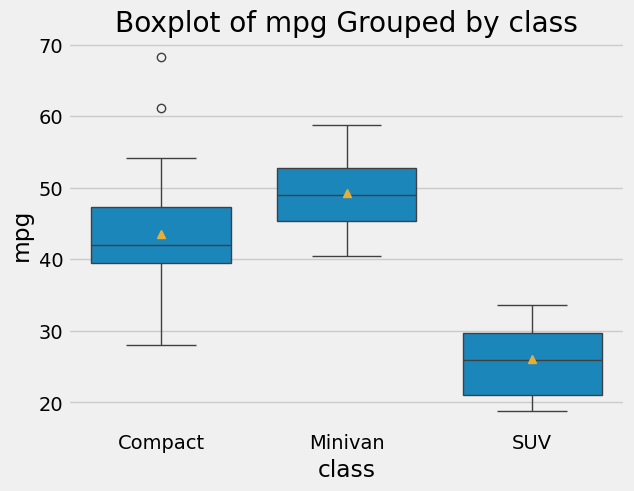

In [33]:
boxes(cars, 'mpg', 'class', True)

## What does an ANOVA do? ##

The grand mean is the mean of all the data lumped together, ignoring the groups, we denote it by $\displaystyle \overline{X}_{GM}$.

Then assume there are $k$ groups.  For group $j$ ( $1\leq j \leq k$) the value $x_{ji}$ refers to the $i^{\mathrm{th}}$ observation in the $j^{\mathrm{th}}$ group.  Also, $\overline{x}_j$ refers to the mean of the group $j$.  



Then:

$$n = \sum_{j=1}^k n_j$$

$$SS_{Total} = \sum_{j=1}^k \sum_{i = 1}^{n_j} (x_{ji} - \overline{X}_{GM})^2$$

$$SS_{Between} = \sum_{j=1}^k n_j(\overline{x}_j - \overline{X}_{GM})^2$$

$$SS_{Within} = \sum_{j = 1}^k \sum_{i=1}^{n_j} (x_{ji} - \overline{x}_j)^2$$


$$SS_{Within} = SS_{Total} - SS_{Between}$$


$$MS_{Between} = \frac{SS_{Between}}{n - k}$$

$$MS_{Within} = \frac{SS_{Within}}{k-1}$$

Finally:

$$F = \frac{MS_{Between}}{MS_{Within}}$$

Then the p-value is determined by finding the area under the appropriate F-distribution beyond this test statistic.  The F-distribution is determined by two different degrees of freedom; the degrees of freedom in the nomimator $n - k$, and the degress of freedom in the denominator, $k-1$.  These are also referred to as the degrees of freedom between groups and the degrees of freedom within groups.  


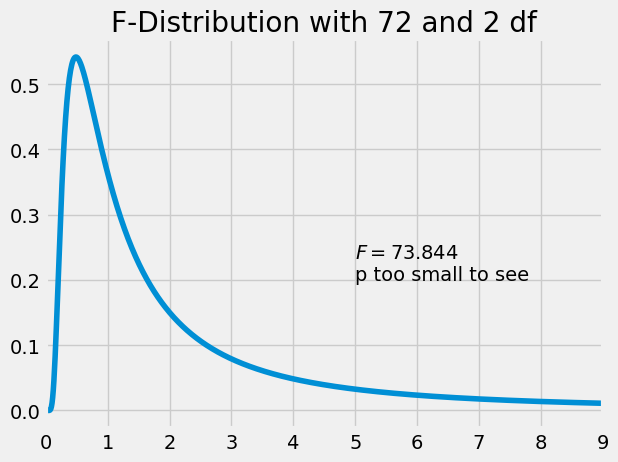

In [34]:
x = np.arange(0.01,9,0.01)
y = stats.f.pdf(x, 72, 2)

plots.xlim(0,9)
plots.plot(x,y)
plots.title("F-Distribution with 72 and 2 df")
plots.text(5, 0.2, "$F = 73.844$\np too small to see");

# <span style="color:blue;font-weight:bold;font-size:1.1em">Example 2: Hours of Sleep</span>

In the **students** table data provided, compare the **Hours of Sleep** of these college students by their **Year in College** using ANOVA and a 0.05 level of significance.

You may uncomment the last row in the cell below this one to see a few rows of the table data we are provided.

In [80]:
students = Table.read_table("ClassData.csv")
#students

### Descriptives

In the **students** table, use the **describes()** function to show the descriptives for numeric column **SleepHours** by grouping column **CollegeYear**.

In [86]:
...

Ellipsis

### Run the ANOVA

We first need a separate array for each class of students:

- Freshmen
- Sophomores
- Juniors
- Seniors

The code below creates these arrays for us using **.where** and **.column**.

In [87]:
Freshmen = students.where('CollegeYear','First').column('SleepHours')
Sophomores = students.where('CollegeYear','Second').column('SleepHours')
Juniors = students.where('CollegeYear','Third').column('SleepHours')
Seniors =  students.where('CollegeYear','Fourth').column('SleepHours')

### Run the ANOVA using Arrays Above

In [88]:
...

Ellipsis

### Reporting Out



#### Create side-by-side Box Plots for these Groups

The box plots, especially if we add the `showmeans = True` option, will help us see what is happening within this ANOVA.

In [89]:
...

Ellipsis

# <span style="color:blue;font-weight:bold;font-size:1.1em">Example 3: Parental Education Impact upon Child</span>

In the **perform** table data provided, compare the **Final Exam Score** of these college students by their **Parental Education** grouping using ANOVA and an $0.05$ level of significance.

You may uncomment the last row in the cell below this one to see a few rows of the table data we are provided.

In [90]:
temp = Table.read_table('https://faculty.ung.edu/rsinn/data/student_performance.csv')
temp2 = temp.where('parental_education', are.contained_in('Bachelors High School Masters'))
temp3 = temp2.select('student_id','gender','parental_education','previous_grade','final_exam_score')
#perform.show(7)

### Descriptives

In the **perform** table, use the **describes()** function to show the descriptives for numeric column **final_exam_score** by grouping column **parental_education**.

In [91]:
...

Ellipsis

### Run the ANOVA by Creating Arrays for all Groups

In [93]:
...

Ellipsis

### Run the ANOVA

In [94]:
...

Ellipsis

### Reporting Out

